In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import AutoMinorLocator, MultipleLocator
from matplotlib.collections import LineCollection
from src.results_paper import *
from src.TimeSeriesAnalysis import *
from IPython.display import clear_output
from src.stability_tests import read_dynamic_bundle, select_dynamic_bundle_row, dynamic_series_from_row
from matplotlib.ticker import FormatStrFormatter
from matplotlib.ticker import MaxNLocator
plt.style.use('properties.mplstyle')


In [2]:
print("usetex:", plt.rcParams['text.usetex'])
print("font.family:", plt.rcParams['font.family'])

usetex: True
font.family: ['serif']


In [4]:
results_folder = "../results/TimeSeries/2D"
create_folder(results_folder)

## 1 COLOR - MULTIPLES $p_0$

In [5]:
df_min_bond = pd.read_csv("../SOP_data/ft_min_max_2D_bond_linear.csv")
df_min_node = pd.read_csv("../SOP_data/ft_min_max_2D_node_linear.csv")
df_min_node

,L,c,type_perc,control_rule,f0,p0,nc,rho,f_T_min,p_min,p_min_err,p_star,p_star_err,f_T_max,p_max,p_max_err,N_samples,N_samples_exec
0,512,0.01,node,linear,0.2,0.8,1,1.0,0.208421,0.601715,0.000094,0.601715,0.000094,0.3,0.611404,0.000062,702,698
1,1024,0.01,node,linear,0.2,0.8,1,1.0,0.162632,0.597567,0.000057,0.597567,0.000057,0.3,0.609864,0.000039,502,500
2,2048,0.01,node,linear,0.2,0.8,1,1.0,0.132105,0.595484,0.000036,0.595484,0.000036,0.3,0.609268,0.000024,402,396
3,4096,0.01,node,linear,0.2,0.8,1,1.0,0.116842,0.594549,0.000029,0.594549,0.000029,0.3,0.609037,0.000020,202,199
4,8192,0.01,node,linear,0.2,0.8,1,1.0,0.096500,0.593876,0.000025,0.593876,0.000025,0.3,0.609087,0.000017,102,100
5,16384,0.01,node,linear,0.2,0.8,1,1.0,0.082000,0.593427,0.000017,0.593427,0.000017,0.3,0.609320,0.000014,52,52
6,512,0.05,node,linear,0.2,0.8,1,1.0,0.207260,0.601877,0.000079,0.601877,0.000079,0.3,0.601877,0.000079,704,702
7,645,0.05,node,linear,0.2,0.8,1,1.0,0.193543,0.600268,0.000067,0.600268,0.000067,0.3,0.600268,0.000067,604,603
8,813,0.05,node,linear,0.2,0.8,1,1.0,0.180704,0.598976,0.000063,0.598976,0.000063,0.3,0.598976,0.000063,554,553
9,1024,0.05,node,linear,0.2,0.8,1,1.0,0.169000,0.597897,0.000036,0.597897,0.000036,0.3,0.597897,0.000036,1004,1003


## Initial Conditions effects - $p(0)$, $f(0)$

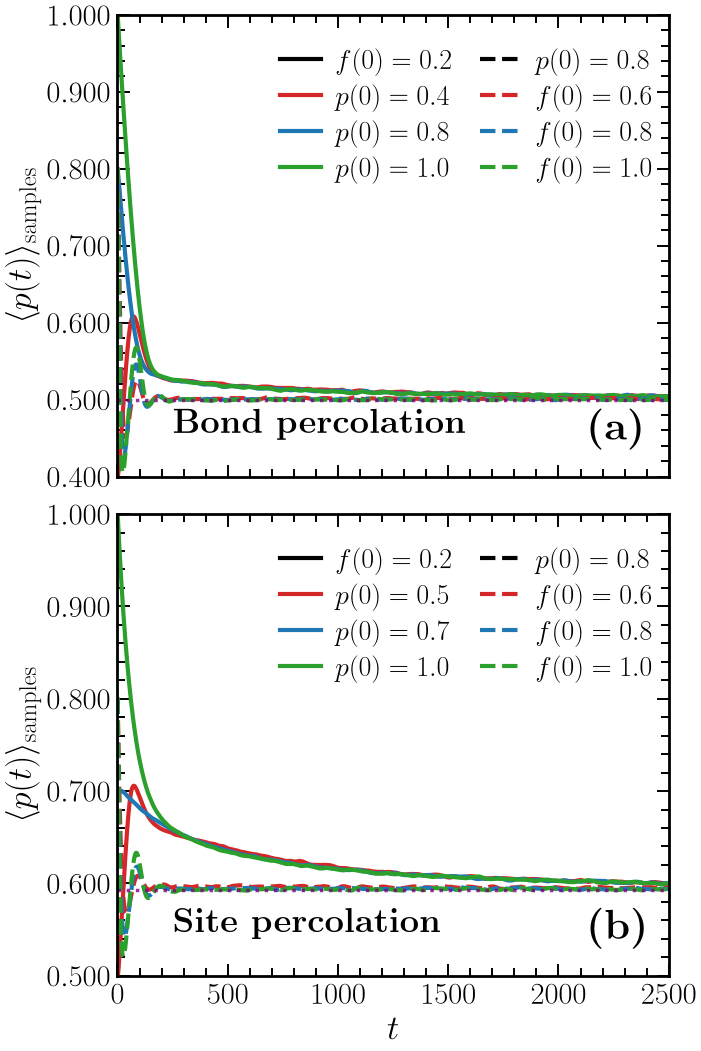

In [49]:
import os
import numpy as np
import matplotlib.pyplot as plt

from matplotlib.lines import Line2D
from matplotlib.ticker import FormatStrFormatter


# ============================================================
# PARAMETERS
# ============================================================

nc = 1
dim = 2
c = 0.05
rho = 1 / nc
L = 16384

modes = ['bond', 'node']
pc = [0.5, 0.59274605079016]

ft = 0.1
rule_update = 'linear'

fixed_f0 = 0.2
fixed_p0 = 0.8

colors = ['tab:red', 'tab:blue', 'tab:green']

p0_values = {
    'bond': [0.4, 0.8, 1.0],
    'node': [0.5, 0.7, 1.0]
}

f0_values = [0.6, 0.8, 1.0]


# ============================================================
# FIGURE CONFIGURATION
# ============================================================

base = 7

fig, axes = plt.subplots(
    2, 1,
    figsize=(base, base * 1.5),
    constrained_layout=True,
    sharex=True
)

lw = 3.0

fs_legend = 20
fs_texts = 25
fs_ticks = 22
fs_panel = 30


# ============================================================
# POSITION CONTROLS
# ============================================================

# Legend: upper-right corner
xleg, yleg = 0.98, 0.94

# Percolation type: original position
xtext, ytext = 0.10, 0.08

# Panel labels: original position
xpanel, ypanel = 0.85, 0.08


# ============================================================
# MAIN LOOP
# ============================================================

for idx_mode, mode in enumerate(modes):

    ax = axes[idx_mode]

    bundle_path = (
        f'../SOP_data/published_dynamic/{mode}_percolation/'
        f'num_colors_{nc}/dim_{dim}/L_{L}/fT_constant/'
        f'fT_{ft:.6e}/c_{c:.6e}/rho_{rho:.4e}/'
        'properties_dynamic_bundle.json.xz'
    )

    bundle = read_dynamic_bundle(bundle_path)

    # --------------------------------------------------------
    # FIXED f(0): SOLID LINES
    # --------------------------------------------------------

    for color, p0_value in zip(colors, p0_values[mode]):

        try:
            row = select_dynamic_bundle_row(
                bundle,
                p0=p0_value,
                P0=fixed_f0,
                order=0,
                rule_update=rule_update
            )

            t, p_t, _ = dynamic_series_from_row(
                row,
                observable='pt'
            )

        except ValueError as exc:
            print(
                f'Cannot plot mode={mode}, '
                f'p0={p0_value}, f0={fixed_f0}: {exc}'
            )
            continue

        ax.plot(
            t,
            p_t,
            color=color,
            ls='solid',
            lw=lw,
            label=fr'$p(0)={p0_value:.1f}$'
        )

    # --------------------------------------------------------
    # FIXED p(0): DASHED LINES
    # --------------------------------------------------------

    for color, f0_value in zip(colors, f0_values):

        try:
            row = select_dynamic_bundle_row(
                bundle,
                p0=fixed_p0,
                P0=f0_value,
                order=0,
                rule_update=rule_update
            )

            t, p_t, _ = dynamic_series_from_row(
                row,
                observable='pt'
            )

        except ValueError as exc:
            print(
                f'Cannot plot mode={mode}, '
                f'p0={fixed_p0}, f0={f0_value}: {exc}'
            )
            continue

        ax.plot(
            t,
            p_t,
            color=color,
            ls='dashed',
            lw=lw,
            label=fr'$f(0)={f0_value:.1f}$'
        )

    # --------------------------------------------------------
    # REFERENCE LINE
    # --------------------------------------------------------

    ax.axhline(
        pc[idx_mode],
        color='purple',
        lw=2.5,
        ls='dotted',
        alpha=0.8
    )

    # --------------------------------------------------------
    # AXES
    # --------------------------------------------------------

    ax.set_xlim(0, 2500)

    ax.set_ylim(
        0.4 if mode == 'bond' else 0.5,
        1.0
    )

    ax.xaxis.set_major_formatter(
        FormatStrFormatter(r'$%.0f$')
    )

    ax.yaxis.set_major_formatter(
        FormatStrFormatter(r'$%.3f$')
    )

    ax.tick_params(
        axis='both',
        labelsize=fs_ticks
    )

    ax.set_ylabel(
        r'$\langle p(t) \rangle_{\mathrm{samples}}$',
        fontsize=25
    )

    if mode == 'node':
        ax.set_xlabel(
            r'$t$',
            fontsize=25
        )

    # --------------------------------------------------------
    # PERCOLATION TYPE — ARIAL BOLD
    # --------------------------------------------------------

    name = 'Bond' if mode == 'bond' else 'Site'

    ax.text(
        xtext,
        ytext,
        rf'\textbf{{{name} percolation}}',
        transform=ax.transAxes,
        fontsize=fs_texts,
        ha='left',
        va='bottom'
    )

    # --------------------------------------------------------
    # PANEL LABEL — ARIAL BOLD
    # --------------------------------------------------------

    ax.text(
        0.85,
        0.08,
        rf'\textbf{{({chr(97 + idx_mode)})}}',
        transform=ax.transAxes,
        fontsize=30,
        ha='left',
        va='baseline'
    )

    # --------------------------------------------------------
    # LEGEND HANDLES
    # --------------------------------------------------------

    legend_handles = [
        Line2D(
            [0], [0],
            color='black',
            lw=lw,
            ls='solid'
        ),

        *[
            Line2D(
                [0], [0],
                color=color,
                lw=lw,
                ls='solid'
            )
            for color in colors
        ],

        Line2D(
            [0], [0],
            color='black',
            lw=lw,
            ls='dashed'
        ),

        *[
            Line2D(
                [0], [0],
                color=color,
                lw=lw,
                ls='dashed'
            )
            for color in colors
        ]
    ]

    legend_labels = [
        r'$f(0)=0.2$',

        *[
            fr'$p(0)={p0_value:.1f}$'
            for p0_value in p0_values[mode]
        ],

        r'$p(0)=0.8$',

        *[
            fr'$f(0)={f0_value:.1f}$'
            for f0_value in f0_values
        ]
    ]

    # --------------------------------------------------------
    # LEGEND — UPPER RIGHT, INSIDE AXES
    # --------------------------------------------------------

    ax.legend(
        handles=legend_handles,
        labels=legend_labels,
        loc='upper right',
        bbox_to_anchor=(xleg, yleg),
        bbox_transform=ax.transAxes,
        ncol=2,
        fontsize=fs_legend,
        frameon=False,
        alignment='left',
        labelspacing=0.3,
        columnspacing=1.0,
        borderaxespad=0.0,
        handlelength=1.5,
        handletextpad=0.5
    )


# ============================================================
# SAVE
# ============================================================

os.makedirs(
    results_folder,
    exist_ok=True
)

fig.savefig(
    f'{results_folder}/Initial_Conditions_L_{L}.pdf',
    format='pdf',
    dpi=300
)

plt.show()

## feedback strength effects - $c$

Plotting mode=bond, L=1024, c=0.01, f_T=0.300000
Plotting mode=bond, L=1024, c=0.10, f_T=0.300000
Plotting mode=bond, L=4096, c=0.01, f_T=0.300000
Plotting mode=bond, L=4096, c=0.10, f_T=0.300000
Plotting mode=bond, L=16384, c=0.01, f_T=0.300000
Plotting mode=bond, L=16384, c=0.10, f_T=0.300000
Plotting mode=node, L=1024, c=0.01, f_T=0.300000
Plotting mode=node, L=1024, c=0.10, f_T=0.300000
Plotting mode=node, L=4096, c=0.01, f_T=0.300000
Plotting mode=node, L=4096, c=0.10, f_T=0.300000
Plotting mode=node, L=16384, c=0.01, f_T=0.300000
Plotting mode=node, L=16384, c=0.10, f_T=0.300000


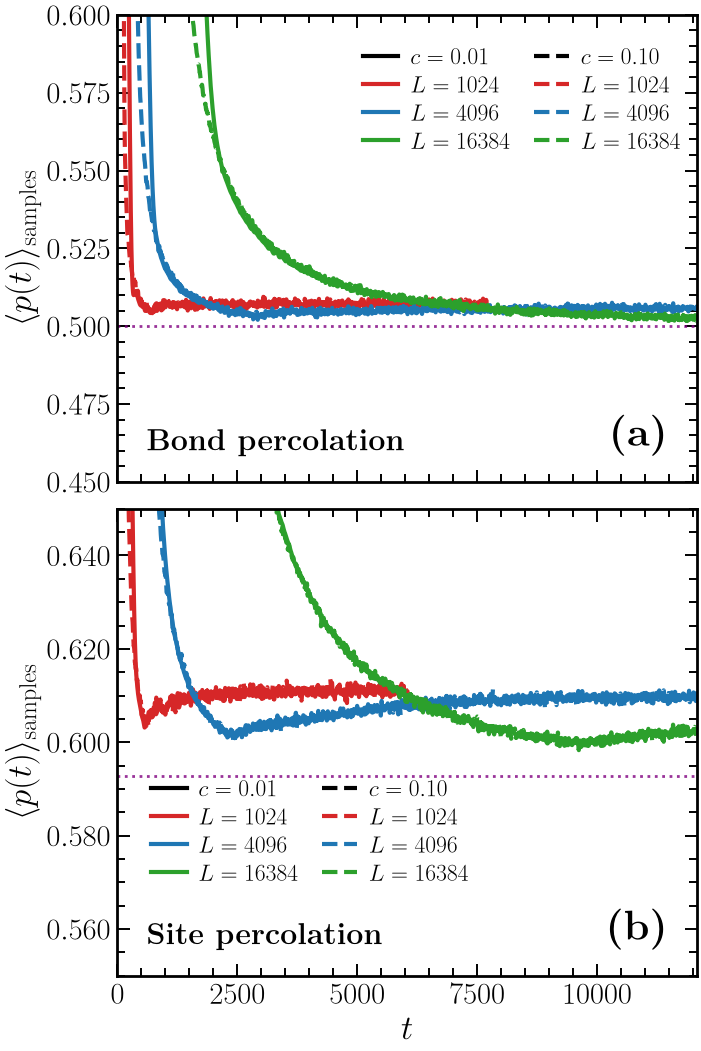

In [6]:
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from matplotlib.lines import Line2D
from matplotlib.ticker import FormatStrFormatter


# ============================================================
# PARAMETERS
# ============================================================

nc = 1
dim = 2
rho = 1 / nc

modes = ['bond', 'node']

L_values = [1024, 4096, 16384]
c_values = [0.01, 0.10]

ft = 0.3

p0_fixed = 0.8
P0_fixed = 0.2

rule_update = 'linear'

pc = [0.5, 0.59274605079016]

L_colors = ['tab:red', 'tab:blue', 'tab:green']

colors_by_L = dict(zip(L_values, L_colors))

ls_by_c = {
    0.01: 'solid',
    0.10: 'dashed'
}


# ============================================================
# FIGURE CONFIGURATION
# ============================================================

base = 7

fig, axes = plt.subplots(
    2, 1,
    figsize=(base, base * 1.5),
    constrained_layout=True,
    sharex=True
)


# ============================================================
# FONT AND LINE SETTINGS
# ============================================================

lw = 3.0

fs_legend = 17
fs_texts = 22
fs_ticks = 22
fs_labels = 30


# ============================================================
# POSITION CONTROLS
# ============================================================

# Legend: upper-left corner of its bounding box
xleg = 0.05
yleg = 0.43

# Percolation title: below the legend
xtext = xleg
ytext = 0.055

# Panel labels: bottom-right corner
xlabel_panel = 0.95
ylabel_panel = 0.055


# ============================================================
# DATA
# ============================================================

t_max_by_mode = {
    mode: np.inf
    for mode in modes
}


# ============================================================
# MAIN LOOP
# ============================================================

for idx_mode, mode in enumerate(modes):

    ax = axes[idx_mode]

    curve_handles = []

    # --------------------------------------------------------
    # PLOT DATA
    # --------------------------------------------------------

    for L in L_values:

        for c_value in c_values:

            bundle_root = Path(
                f'../SOP_data/published_dynamic/'
                f'{mode}_percolation/'
                f'num_colors_{nc}/dim_{dim}/'
                f'L_{L}/fT_constant'
            )

            bundle_path = bundle_root / (
                f'fT_{ft:.6e}/'
                f'c_{c_value:.6e}/'
                f'rho_{rho:.4e}/'
                'properties_dynamic_bundle.json.xz'
            )

            try:

                bundle = read_dynamic_bundle(bundle_path)

                row = select_dynamic_bundle_row(
                    bundle,
                    p0=p0_fixed,
                    P0=P0_fixed,
                    order=0,
                    rule_update=rule_update
                )

                t, p_t, _ = dynamic_series_from_row(
                    row,
                    observable='pt'
                )

            except (FileNotFoundError, ValueError) as exc:

                print(
                    f'Cannot plot mode={mode}, '
                    f'L={L}, '
                    f'c={c_value}, '
                    f'f_T={ft:.6f}: {exc}'
                )

                continue

            handle, = ax.plot(
                t,
                p_t,
                color=colors_by_L[L],
                ls=ls_by_c[c_value],
                lw=lw,
                label=fr'$L={L}$, $c={c_value:.2f}$'
            )

            curve_handles.append(handle)

            t_max_by_mode[mode] = min(
                t_max_by_mode[mode],
                np.nanmax(t)
            )

            print(
                f'Plotting mode={mode}, '
                f'L={L}, '
                f'c={c_value:.2f}, '
                f'f_T={ft:.6f}'
            )

    # --------------------------------------------------------
    # REFERENCE LINE
    # --------------------------------------------------------

    ax.axhline(
        pc[idx_mode],
        color='purple',
        lw=2.0,
        ls='dotted',
        alpha=0.8
    )

    # --------------------------------------------------------
    # AXES
    # --------------------------------------------------------

    t_max = t_max_by_mode[mode]

    if np.isfinite(t_max) and t_max > 0:
        ax.set_xlim(0, t_max*2)

    if mode == 'bond':
        ax.set_ylim(0.45, 0.6)
    else:
        ax.set_ylim(0.55, 0.65)

    ax.xaxis.set_major_formatter(
        FormatStrFormatter(r'$%.0f$')
    )

    ax.yaxis.set_major_formatter(
        FormatStrFormatter(r'$%.3f$')
    )

    ax.tick_params(
        axis='both',
        labelsize=fs_ticks
    )

    ax.set_ylabel(
        r'$\langle p(t) \rangle_{\mathrm{samples}}$',
        fontsize=25
    )

    if mode == 'node':
        ax.set_xlabel(
            r'$t$',
            fontsize=25
        )

    # --------------------------------------------------------
    # LEGEND
    # --------------------------------------------------------

    legend_handles = [
        Line2D(
            [0], [0],
            color='black',
            lw=lw,
            ls='solid'
        ),

        *[
            Line2D(
                [0], [0],
                color=colors_by_L[L],
                lw=lw,
                ls='solid'
            )
            for L in L_values
        ],

        Line2D(
            [0], [0],
            color='black',
            lw=lw,
            ls='dashed'
        ),

        *[
            Line2D(
                [0], [0],
                color=colors_by_L[L],
                lw=lw,
                ls='dashed'
            )
            for L in L_values
        ]
    ]

    legend_labels = [
        r'$c=0.01$',
        *[fr'$L={L}$' for L in L_values],

        r'$c=0.10$',
        *[fr'$L={L}$' for L in L_values]
    ]

    leg_loc = 'upper right' if mode == 'bond' else 'upper left'
    leg_anchor = (0.98, 0.94) if mode == 'bond' else (xleg, yleg)

    legend = ax.legend(
        handles=legend_handles,
        labels=legend_labels,

        loc=leg_loc,

        bbox_to_anchor=leg_anchor,
        bbox_transform=ax.transAxes,

        ncol=2,

        fontsize=fs_legend,

        frameon=False,

        alignment='left',

        labelspacing=0.3,
        columnspacing=1.0,

        borderaxespad=0.0,

        handlelength=1.5,
        handletextpad=0.5
    )

    # --------------------------------------------------------
    # PERCOLATION TYPE
    # --------------------------------------------------------

    name = 'Bond' if mode == 'bond' else 'Site'

    ax.text(
        xtext,
        ytext,
        rf'\textbf{{{name} percolation}}',
        transform=ax.transAxes,
        fontsize=fs_texts,
        ha='left',
        va='bottom'
    )

    # --------------------------------------------------------
    # PANEL LABEL
    # --------------------------------------------------------

    ax.text(
        xlabel_panel,
        ylabel_panel,
        rf'\textbf{{({chr(97 + idx_mode)})}}',
        transform=ax.transAxes,
        fontsize=fs_labels,
        ha='right',
        va='bottom'
    )


# ============================================================
# SAVE
# ============================================================

Path(results_folder).mkdir(
    parents=True,
    exist_ok=True
)

fig.savefig(
    f'{results_folder}/c_effects_L_fT{ft}.pdf',
    format='pdf',
    bbox_inches='tight'
)

plt.show()

## Target fractions effects - $f_\mathrm{T}$

Plotting mode=bond, L=1024, f_T=0.3000000
Plotting mode=bond, L=1024, f_T=0.2156639
Plotting mode=bond, L=16384, f_T=0.3000000
Plotting mode=bond, L=16384, f_T=0.0896590
Plotting mode=node, L=1024, f_T=0.3000000
Plotting mode=node, L=1024, f_T=0.1690000
Plotting mode=node, L=16384, f_T=0.3000000
Plotting mode=node, L=16384, f_T=0.0741641


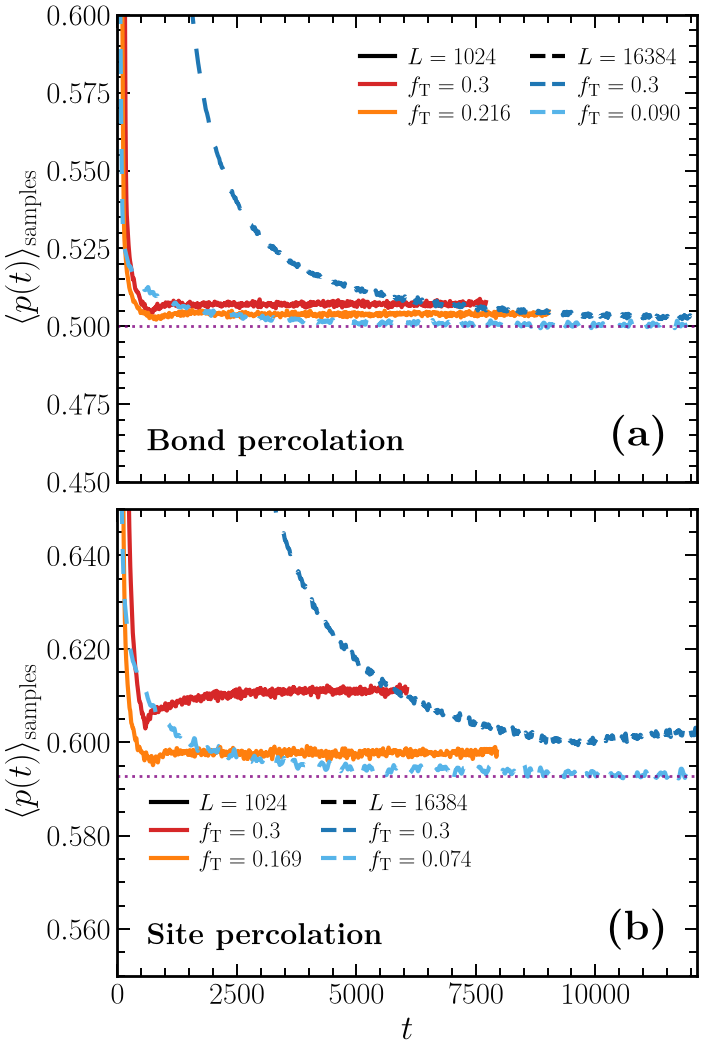

In [7]:
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from matplotlib.lines import Line2D
from matplotlib.ticker import FormatStrFormatter


# ============================================================
# PARAMETERS
# ============================================================

nc = 1
dim = 2
rho = 1 / nc

c_fixed = 0.05

modes = ['bond', 'node']

L_values = [1024, 16384]

ft_fixed = 0.3

p0_fixed = 0.8
P0_fixed = 0.2

rule_update = 'linear'

pc = [0.5, 0.59274605079016]


# ============================================================
# COLORS AND LINE STYLES
# ============================================================

ls_by_L = {
    1024: 'solid',
    16384: (0, (6, 6))
}

color_by_curve = {
    (1024, 'fixed'): 'tab:red',
    (1024, 'min'): 'tab:orange',
    (16384, 'fixed'): 'tab:blue',
    (16384, 'min'): '#56B4E9'
}


# ============================================================
# FIGURE CONFIGURATION
# ============================================================

base = 7

fig, axes = plt.subplots(
    2, 1,
    figsize=(base, base * 1.5),
    constrained_layout=True,
    sharex=True
)


# ============================================================
# FONT AND LINE SETTINGS
# ============================================================

lw = 3.0

fs_legend = 17
fs_texts = 22
fs_ticks = 22
fs_labels = 30


# ============================================================
# POSITION CONTROLS
# ============================================================

# Legenda: parte inferior esquerda
xleg, yleg = 0.05, 0.40

# Bond/Site percolation
xtext, ytext = 0.05, 0.055

# Labels (a) e (b)
xpanel, ypanel = 0.95, 0.055


# ============================================================
# DATA
# ============================================================

t_max_by_mode = {
    mode: np.inf
    for mode in modes
}


# ============================================================
# MAIN LOOP
# ============================================================

for idx_mode, mode in enumerate(modes):

    ax = axes[idx_mode]

    df_ft = df_min_bond if mode == 'bond' else df_min_node

    ft_min_by_L = {}

    # --------------------------------------------------------
    # PLOT DATA
    # --------------------------------------------------------

    for L in L_values:

        row_ft = df_ft[
            np.isclose(df_ft['c'].astype(float), c_fixed)
            & (df_ft['L'].astype(int) == L)
            & (df_ft['nc'].astype(int) == nc)
        ]

        if row_ft.empty:

            print(
                f'No f_T minimum found for '
                f'mode={mode}, L={L}, c={c_fixed}'
            )

            continue

        ft_min_by_L[L] = float(
            row_ft['f_T_min'].iloc[0]
        )

        bundle_root = Path(
            f'../SOP_data/published_dynamic/'
            f'{mode}_percolation/'
            f'num_colors_{nc}/dim_{dim}/'
            f'L_{L}/fT_constant'
        )

        candidates = list(
            bundle_root.glob(
                f'fT_*/c_{c_fixed:.6e}/'
                f'rho_{rho:.4e}/'
                'properties_dynamic_bundle.json.xz'
            )
        )

        if not candidates:

            print(
                f'No bundles found for '
                f'mode={mode}, L={L}, c={c_fixed}'
            )

            continue

        for ft_kind, ft_requested in [
            ('fixed', ft_fixed),
            ('min', ft_min_by_L[L])
        ]:

            bundle_path = min(
                candidates,
                key=lambda path: abs(
                    float(
                        path.parents[2].name.removeprefix('fT_')
                    ) - ft_requested
                )
            )

            ft_actual = float(
                bundle_path.parents[2].name.removeprefix('fT_')
            )

            try:

                bundle = read_dynamic_bundle(bundle_path)

                row = select_dynamic_bundle_row(
                    bundle,
                    p0=p0_fixed,
                    P0=P0_fixed,
                    order=0,
                    rule_update=rule_update
                )

                t, p_t, _ = dynamic_series_from_row(
                    row,
                    observable='pt'
                )

            except (FileNotFoundError, ValueError) as exc:

                print(
                    f'Cannot plot mode={mode}, '
                    f'L={L}, f_T={ft_actual:.7f}: {exc}'
                )

                continue

            color = color_by_curve[(L, ft_kind)]

            ax.plot(
                t,
                p_t,
                color=color,
                ls=ls_by_L[L],
                lw=lw,
                label=fr'$L={L}$, $f_\mathrm{{T}}={ft_actual:.3f}$'
            )

            t_max_by_mode[mode] = min(
                t_max_by_mode[mode],
                np.nanmax(t)
            )

            print(
                f'Plotting mode={mode}, '
                f'L={L}, f_T={ft_actual:.7f}'
            )

    # --------------------------------------------------------
    # REFERENCE LINE
    # --------------------------------------------------------

    ax.axhline(
        pc[idx_mode],
        color='purple',
        ls = 'dotted',
        lw=2.0,
        alpha=0.8
    )

    # --------------------------------------------------------
    # AXES
    # --------------------------------------------------------

    t_max = t_max_by_mode[mode]

    if np.isfinite(t_max) and t_max > 0:
        ax.set_xlim(0, t_max*2)

    if mode == 'bond':
        ax.set_ylim(0.45, 0.6)
    else:
        ax.set_ylim(0.55, 0.65)

    ax.xaxis.set_major_formatter(
        FormatStrFormatter(r'$%.0f$')
    )

    ax.yaxis.set_major_formatter(
        FormatStrFormatter(r'$%.3f$')
    )

    ax.tick_params(
        axis='both',
        labelsize=fs_ticks
    )

    ax.set_ylabel(
        r'$\langle p(t) \rangle_{\mathrm{samples}}$',
        fontsize=25
    )

    if mode == 'node':
        ax.set_xlabel(
            r'$t$',
            fontsize=25
        )

    # --------------------------------------------------------
    # LEGEND HANDLES
    # --------------------------------------------------------

    legend_handles = []
    legend_labels = []

    for L in L_values:

        if L not in ft_min_by_L:
            continue

        legend_ls = 'solid' if L == 1024 else 'dashed'

        legend_handles.extend([
            Line2D(
                [0], [0],
                color='black',
                lw=lw,
                ls=legend_ls
            ),
            Line2D(
                [0], [0],
                color=color_by_curve[(L, 'fixed')],
                lw=lw,
                ls=legend_ls
            ),
            Line2D(
                [0], [0],
                color=color_by_curve[(L, 'min')],
                lw=lw,
                ls=legend_ls
            ),
        ])

        legend_labels.extend([
            fr'$L={L}$',
            fr'$f_\mathrm{{T}}={ft_fixed:.1f}$',
            fr'$f_\mathrm{{T}}={ft_min_by_L[L]:.3f}$',
        ])

    leg_loc = 'upper right' if mode == 'bond' else 'upper left'
    leg_anchor = (0.98, 0.94) if mode == 'bond' else (xleg, yleg)

    legend = ax.legend(
        handles=legend_handles,
        labels=legend_labels,
        loc=leg_loc,
        bbox_to_anchor=leg_anchor,
        bbox_transform=ax.transAxes,
        ncol=2,
        fontsize=fs_legend,
        frameon=False,
        alignment='left',
        labelspacing=0.3,
        columnspacing=0.8,
        borderaxespad=0.0,
        handlelength=1.5,
        handletextpad=0.5
    )

    # --------------------------------------------------------
    # PERCOLATION TYPE — LATEX BOLD
    # --------------------------------------------------------

    name = 'Bond' if mode == 'bond' else 'Site'

    ax.text(
        xtext,
        ytext,
        rf'\textbf{{{name} percolation}}',
        transform=ax.transAxes,
        fontsize=fs_texts,
        ha='left',
        va='bottom'
    )

    # --------------------------------------------------------
    # PANEL LABEL — LATEX BOLD
    # --------------------------------------------------------

    ax.text(
        xpanel,
        ypanel,
        rf'\textbf{{({chr(97 + idx_mode)})}}',
        transform=ax.transAxes,
        fontsize=fs_labels,
        ha='right',
        va='bottom'
    )


# ============================================================
# SAVE
# ============================================================

Path(results_folder).mkdir(
    parents=True,
    exist_ok=True
)

fig.savefig(
    f'{results_folder}/fT_effects_L.pdf',
    format='pdf'
)

plt.show()

## Amostras únicas: listas de estabilização e redes bond/node

`load_growth_test_stabilization_series` retorna somente listas numéricas calculadas com o alisamento, os blocos e a diferença finita do estimador `growth_test`. A célula abaixo deixa as séries da amostra bond em variáveis para você criar seus próprios plots:

- `t_pt` e `p_t`: tempo e série $p(t)$;
- `p_t_moving_average`: média móvel centrada;
- `t_blocks` e `p_t_block_mean`: médias por blocos;
- `s_block_variation`: $s(k)=|j_w(k+1)-j_w(k)|$;
- `t_derivative` e `derivative`: tempo e derivada $s'(t)$.

A mesma célula plota somente as redes em subplot 1×2. Os parâmetros são iguais, com $f_{T,\min}=0.2147368$ para bond e $f_{T,\min}=0.169$ para node. No CSV de node, o tipo aparece como `site`; a amostra é executada como `node`. As duas usam a seed `20260928`. O título de cada painel identifica o tipo de percolação; o estilo e a marca de $z_{\mathrm{stab}}$ são mantidos.


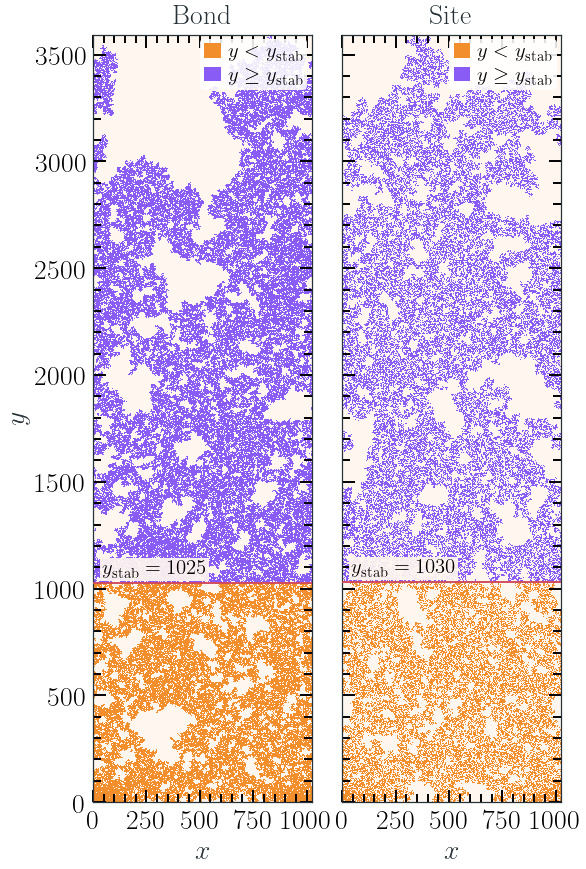

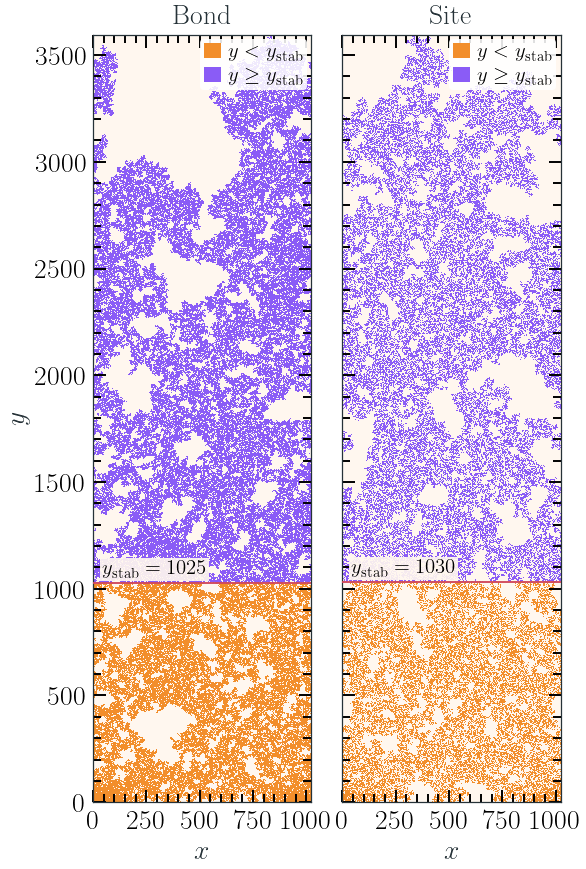

In [7]:
from pathlib import Path
from IPython.display import display

from pathlib import Path

raw_root = Path("../SOP_data/raw_growth_test_dynamic")

bond_dir = raw_root / (
    "bond_percolation/num_colors_1/dim_2/L_1024/"
    "fT_constant/fT_1.961397e-01/c_5.000000e-02/rho_1.0000e+00"
)
node_dir = raw_root / (
    "node_percolation/num_colors_1/dim_2/L_1024/"
    "fT_constant/fT_1.690000e-01/c_5.000000e-02/rho_1.0000e+00"
)

sample_json_bond = next((bond_dir / "data").glob("*.json"))
sample_json_node = next((node_dir / "data").glob("*.json"))

sample_network_bond = bond_dir / "network" / f"{sample_json_bond.stem}.bin"
sample_network_node = node_dir / "network" / f"{sample_json_node.stem}.bin"

network_figure, network_axes = plt.subplots(
    1, 2, figsize=(5.8, 9.0), sharey=True, constrained_layout=True
)
network_figure.set_constrained_layout_pads(
    w_pad=0.02, h_pad=0.02, wspace=0.01, hspace=0.02
)
plot_growth_test_network(
    sample_json_bond,
    ax=network_axes[0],
    title="Bond",
    x_label=r"$x$",
    y_label=r"$y$",
    fs_labels=20,
    fs_zstab=15,
    L=1024,
    legend_label_stab=r"$y<y_{\mathrm{stab}}$",
    legend_label_posstab=r"$y \geq y_{\mathrm{stab}}$",
    fs_legend=15,
)
plot_growth_test_network(
    sample_json_node,
    ax=network_axes[1],
    title="Site",
    x_label=r"$x$",
    y_label=r"",
    fs_labels=20,
    fs_zstab=15,
    L=1024,
    legend_label_stab=r"$y<y_{\mathrm{stab}}$",
    legend_label_posstab=r"$y \geq y_{\mathrm{stab}}$",
    fs_legend=15,
)
display(network_figure)
network_figure.savefig(
    "../Networks/L_1024_ftmin_c_0.05_P0_0.2_p0_0.8_nc_1/results/subgraphs_bond_node_L1024_ftmin.pdf",
    dpi=400,
    bbox_inches="tight",
    facecolor="white",
)
network_figure.savefig(
    "../Networks/L_1024_ftmin_c_0.05_P0_0.2_p0_0.8_nc_1/results/subgraphs_bond_node_L1024_ftmin_seed20260928.svg",
    format="svg",
    bbox_inches="tight",
    facecolor="white",
)


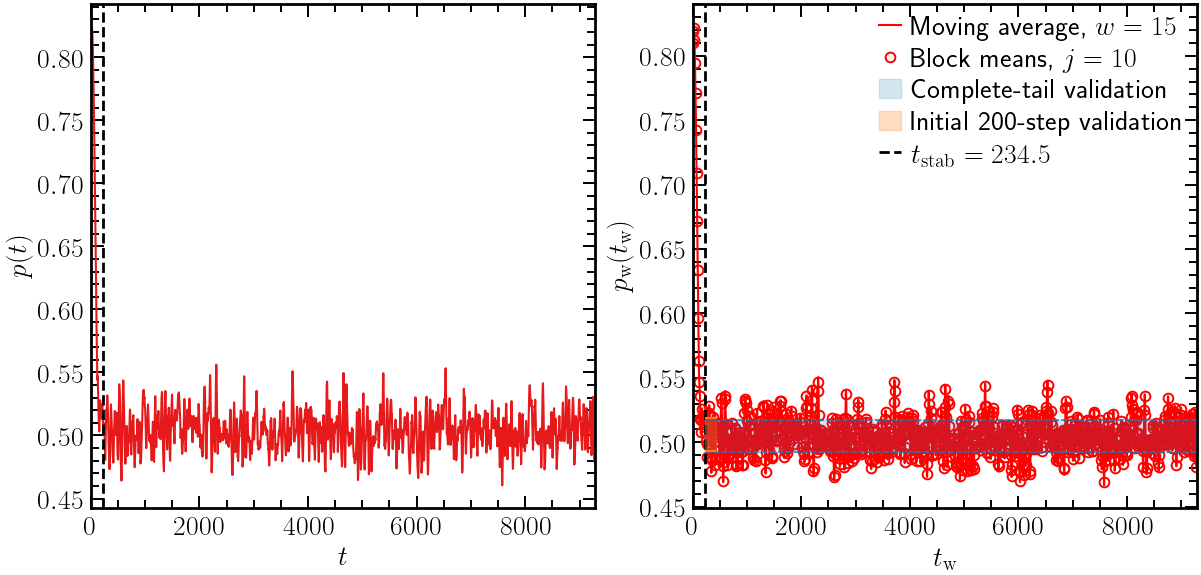

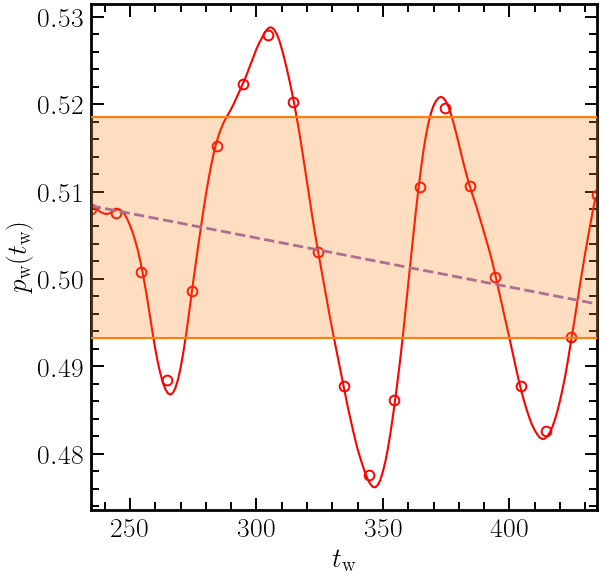

In [34]:
# Séries da amostra bond prontas para os plots personalizados.
import json

sample_series = load_growth_test_stabilization_series(sample_json_bond)
with open(sample_json_bond, "r", encoding="utf-8") as _handle:
    sample_payload = json.load(_handle)

stab_meta = sample_payload["meta"]
t_stab = float(stab_meta["t_eq"])
stab_window = int(stab_meta["growth_test_t_eq_validation_window_steps"])
stab_rel_tol = float(stab_meta["growth_test_equilibrium_effective_rel_tol"])
stab_abs_tol = float(stab_meta["growth_test_equilibrium_abs_tol"])
t_validation_end = t_stab + stab_window

t_pt = np.asarray(sample_series["time"], dtype=float)
p_t = np.asarray(sample_series["p_t"], dtype=float)
p_t_moving_average = np.asarray(sample_series["moving_average"], dtype=float)
t_blocks = np.asarray(sample_series["block_time"], dtype=float)
p_t_block_mean = np.asarray(sample_series["block_mean_pt"], dtype=float)

# Mantidas disponíveis caso sejam necessárias em outras análises.
s_block_variation = np.asarray(sample_series["variation"], dtype=float)
t_derivative = np.asarray(sample_series["derivative_time"], dtype=float)
derivative = np.asarray(sample_series["derivative"], dtype=float)

# Índices e tolerância da janela de validação de 200 passos.
first_idx = int(np.argmin(np.abs(t_blocks - t_stab)))
links_in_window = int(np.ceil(
    stab_window / stab_meta["growth_test_t_eq_window_block"]
))
last_window_idx = min(first_idx + links_in_window, len(p_t_block_mean) - 1)
window_times = t_blocks[first_idx:last_window_idx + 1]
window_values = p_t_block_mean[first_idx:last_window_idx + 1]

edge_count = max(1, len(window_values) // 3)
first_edge_mean = float(np.mean(window_values[:edge_count]))
last_edge_mean = float(np.mean(window_values[-edge_count:]))
window_scale = max(abs(first_edge_mean), abs(last_edge_mean), 1e-12)
window_tolerance = max(stab_abs_tol, stab_rel_tol * window_scale)

# Referência e tolerância calculadas separadamente para a cauda completa.
tail_values = p_t_block_mean[first_idx:]
tail_edge_count = max(1, len(tail_values) // 3)
tail_first_edge_mean = float(np.mean(tail_values[:tail_edge_count]))
tail_last_edge_mean = float(np.mean(tail_values[-tail_edge_count:]))
tail_scale = max(
    abs(tail_first_edge_mean),
    abs(tail_last_edge_mean),
    1e-12,
)
tail_tolerance = max(stab_abs_tol, stab_rel_tol * tail_scale)

fit_slope, fit_intercept = np.polyfit(window_times, window_values, 1)
fit_values = fit_slope * window_times + fit_intercept

# Mesmo padrão visual para o painel completo e para a figura ampliada.
smooth_window = int(stab_meta["growth_test_t_eq_smoothing_window"])
block_window = int(stab_meta["growth_test_t_eq_window_block"])
panel_size = 6
axis_label_size = 20
tick_label_size = 20
major_tick_length = 9
minor_tick_length = 6
tick_width = 1.4
spine_width = 2.0

moving_average_style = {"color": "red", "linewidth": 1.5}
block_mean_style = {
    "marker": "o",
    "linestyle": "none",
    "color": "red",
    "markersize": 7,
    "mew": 1.4,
}

# ------------------------------------------------------------
# Figura principal 1x2: séries completas, sem inset.
# ------------------------------------------------------------
fig_main, axes = plt.subplots(
    1, 2,
    figsize=(2 * panel_size, panel_size),
    constrained_layout=True,
    sharex=False,
)

axes[0].plot(t_pt, p_t)
axes[0].set_xlabel(r"$t$")
axes[0].set_ylabel(r"$p(t)$")

axes[1].plot(
    t_pt,
    p_t_moving_average,
    label=rf"Moving average, $w={smooth_window}$",
    **moving_average_style,
)
axes[1].plot(
    t_blocks,
    p_t_block_mean,
    label=rf"Block means, $j={block_window}$",
    **block_mean_style,
)
axes[1].set_xlabel(r"$t_{\mathrm{w}}$")
axes[1].set_ylabel(r"$p_{\mathrm{w}}(t_{\mathrm{w}})$")

# Bandas horizontais: suas alturas são as tolerâncias usadas pelo critério.
# Azul: cauda completa, de t_stab ao último bloco.
axes[1].fill_between(
    [t_stab, t_blocks[-1]],
    [tail_first_edge_mean - tail_tolerance] * 2,
    [tail_first_edge_mean + tail_tolerance] * 2,
    color="tab:blue",
    alpha=0.18,
    zorder=4,
    label=rf"Complete-tail validation",
)
axes[1].hlines(
    [tail_first_edge_mean - tail_tolerance,
     tail_first_edge_mean + tail_tolerance],
    t_stab,
    t_blocks[-1],
    color="tab:blue",
    linestyle="--",
    linewidth=1.1,
    zorder=5,
)

# Laranja: janela inicial de validação de 200 passos.
axes[1].fill_between(
    [t_stab, t_validation_end],
    [first_edge_mean - window_tolerance] * 2,
    [first_edge_mean + window_tolerance] * 2,
    color="tab:orange",
    alpha=0.26,
    zorder=4.5,
    label=rf"Initial {stab_window}-step validation",
)
axes[1].hlines(
    [first_edge_mean - window_tolerance,
     first_edge_mean + window_tolerance],
    t_stab,
    t_validation_end,
    color="tab:orange",
    linewidth=1.5,
    zorder=5,
)

for ax in axes:
    ax.set_xlim(0, max(t_pt))
    ax.axvline(
        t_stab,
        color="black",
        linestyle="--",
        linewidth=2.0,
        label=rf"$t_{{\mathrm{{stab}}}} = {t_stab:g}$"
    )

axes[1].legend(loc="best")

# ------------------------------------------------------------
# Figura separada: recorte somente da região laranja.
# Pode ser editada e adicionada posteriormente como inset.
# ------------------------------------------------------------
fig_validation, ax_validation = plt.subplots(
    figsize=(panel_size, panel_size),
    constrained_layout=True,
)
t_stab = float(sample_payload["meta"]["t_eq"])
validation_mask = (t_pt >= t_stab) & (t_pt <= t_validation_end)
ax_validation.plot(
    t_pt[validation_mask],
    p_t_moving_average[validation_mask],
    **moving_average_style,
)
ax_validation.plot(
    window_times,
    window_values,
    **block_mean_style,
)
ax_validation.fill_between(
    [t_stab, t_validation_end],
    [first_edge_mean - window_tolerance] * 2,
    [first_edge_mean + window_tolerance] * 2,
    color="tab:orange",
    alpha=0.26,
    zorder=4,
)
ax_validation.hlines(
    [first_edge_mean - window_tolerance, first_edge_mean + window_tolerance],
    t_stab,
    t_validation_end,
    color="tab:orange",
    linewidth=1.5,
    zorder=5,
)
ax_validation.plot(
    window_times,
    fit_values,
    color="tab:purple",
    linestyle="--",
    linewidth=2.0,
)
ax_validation.axvline(
    t_stab,
    color="black",
    linestyle="--",
    linewidth=1.0,
    label=rf"$t_{{\mathrm{{stab}}}} = {t_stab:g}$"
)
ax_validation.set_xlim(t_stab, t_validation_end)
ax_validation.set_xlabel(r"$t_{\mathrm{w}}$")
ax_validation.set_ylabel(r"$p_{\mathrm{w}}(t_{\mathrm{w}})$")

# Mesmas dimensões e propriedades gráficas nos três painéis.
def _apply_common_panel_style(ax):
    ax.set_box_aspect(1)
    ax.xaxis.label.set_size(axis_label_size)
    ax.yaxis.label.set_size(axis_label_size)
    ax.tick_params(
        axis="both", which="major", direction="in", top=True, right=True,
        length=major_tick_length, width=tick_width, labelsize=tick_label_size,
    )
    ax.tick_params(
        axis="both", which="minor", direction="in", top=True, right=True,
        length=minor_tick_length, width=tick_width,
    )
    for spine in ax.spines.values():
        spine.set_linewidth(spine_width)

for _ax in (*axes, ax_validation):
    _apply_common_panel_style(_ax)

# Salva as duas figuras em formato vetorial editável.
stabilization_results_dir = Path(
    "/home/light/Documents/self_organization_percolation/"
    "results/TimeSeries/2D/stabilization"
)
stabilization_results_dir.mkdir(parents=True, exist_ok=True)

fig_main.savefig(
    stabilization_results_dir / "stabilization_series_bond_L1024.svg",
    format="svg",
    bbox_inches="tight",
    facecolor="none",
    transparent=True,
)
fig_validation.savefig(
    stabilization_results_dir / "stabilization_validation_window_bond_L1024.svg",
    format="svg",
    bbox_inches="tight",
    facecolor="none",
    transparent=True,
)

plt.show()
